# tiền xử lý 

## overview lại data

## thư viện sử dụng

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

## Đọc dữ liệu

In [3]:
path = Path(r"..\..\data\raw\train.csv")

df = pd.read_csv(path)
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


* Bộ dữ liệu có 79 cột đặc trưng (features). Dựa trên các đặc trưng này, mô hình của bạn phải dự đoán giá bán của ngôi nhà, được biểu thị bằng cột nhãn (label) có tên là SalePrice.



* Chúng ta sẽ loại bỏ cột Id vì cột này không cần thiết cho quá trình huấn luyện mô hình.

In [4]:
df = df.drop('Id', axis=1)
df.head(3)

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     1460 non-null   int64  
 1   MSZoning       1460 non-null   str    
 2   LotFrontage    1201 non-null   float64
 3   LotArea        1460 non-null   int64  
 4   Street         1460 non-null   str    
 5   Alley          91 non-null     str    
 6   LotShape       1460 non-null   str    
 7   LandContour    1460 non-null   str    
 8   Utilities      1460 non-null   str    
 9   LotConfig      1460 non-null   str    
 10  LandSlope      1460 non-null   str    
 11  Neighborhood   1460 non-null   str    
 12  Condition1     1460 non-null   str    
 13  Condition2     1460 non-null   str    
 14  BldgType       1460 non-null   str    
 15  HouseStyle     1460 non-null   str    
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuilt      1460

## Phân tích sự phân bố giá bán nhà.

## Phân loại dữ liệu

In [ ]:
numberical_continuos=["LotArea", "GrLivArea", "TotalBsmtSF", "GarageArea", "MasVnrArea", "LotFrontage"]
numberical_count=["FullBath", "HalfBath", "BedroomAbvGr", "TotRmsAbvGrd", "GarageCars", "Fireplaces"]
ordinal_categorical=["ExterQual", "ExterCond", "KitchenQual", "HeatingQC", "BsmtQual", "BsmtCond", "GarageQual", "GarageCond", "FireplaceQu"]
nominal_categorical= ["Neighborhood", "MSZoning", "BldgType", "HouseStyle", "RoofStyle", "Exterior1st", "Exterior2nd", "SaleType", "SaleCondition"]
Binary= ["CentralAir", "Street"]
Special_Coded_Category= ["MSSubClass", "MoSold", "YrSold"]
Target= ["SalePrice"]
Id=["Id"]

- Biến số liên tục (Numerical Continuous): Đại diện cho các phép đo vật lý (diện tích). Hợp lệ để sử dụng hệ số tương quan Pearson và chuẩn hóa mạnh (StandardScaler).
- Biến số đếm (Numerical Count): Ví dụ như FullBath (số phòng tắm). Không nên chuẩn hóa mạnh như biến liên tục và hệ số tương quan hạng Spearman sẽ phản ánh chính xác xu hướng đơn điệu hơn là Pearson.
- Biến hạng mục có thứ bậc (Ordinal Categorical): Ví dụ ExterQual. Các giá trị có sự hơn kém rõ ràng (Excellent > Good > Average > Fair > Poor). Do đó, phải sử dụng OrdinalEncoder để mô hình hiểu được tính thứ bậc này, thay vì One-Hot.
- Biến hạng mục định danh (Nominal Categorical): Ví dụ Neighborhood. Không có thứ tự tự nhiên giữa các khu vực. Bắt buộc dùng One-Hot Encoding để tránh việc mô hình gán trọng số ngẫu nhiên cho các mã danh mục.
- Hạng mục mã hóa đặc biệt (Special Coded Category): Đây là nhóm quan trọng nhất cần lưu ý.
- - Biến MSSubClass (Mã loại nhà) có các giá trị: 20, 30, 40, ..., 190.
- - Nếu giữ nguyên định dạng số, các thuật toán hồi quy tuyến tính hoặc câyquyết định sẽ nội suy sai lệch rằng nhà mã 120 lớn hơn nhà mã 20 sáu lần, tạo ra các mối quan hệ toán học giả (spurious relationships).
- - Tương tự, MoSold (Tháng bán) và YrSold (Năm bán) mang tính chu kỳ và phân loại, không mang tính định lượng liên tục. Do đó, quy tắc xử lý là bắt buộc chuyển sang string (chuỗi) và sử dụng One-Hot Encoding.

## kiểm tra dữ liệu thiếu

In [24]:
def missing_values(data:pd.DataFrame,cols):
    for col in cols:
        per=len(data[col])
        missingper=(data[col].isnull().sum())/per*100
        if(missingper >0):
            print(f"{col}:{missingper:.2f}")

In [25]:
cols=df.columns.to_list()
missing_values(df,cols)

LotFrontage:17.74
Alley:93.77
MasVnrType:59.73
MasVnrArea:0.55
BsmtQual:2.53
BsmtCond:2.53
BsmtExposure:2.60
BsmtFinType1:2.53
BsmtFinType2:2.60
Electrical:0.07
FireplaceQu:47.26
GarageType:5.55
GarageYrBlt:5.55
GarageFinish:5.55
GarageQual:5.55
GarageCond:5.55
PoolQC:99.52
Fence:80.75
MiscFeature:96.30


* Quy trình xác định missing values gồm 3 cơ sở:
- thiếu do không có tiện ích :do không có các tiện ích khi theo ngôi nhà (hồ bơi, lò sưởi...)
- Vắng mặt thông số vật lý: do ngôi nhà không có gara, diện tích gara
- Khuyết thiếu thực sự :biến liên tục bị thiếu thực sự như LotFrontage và biến phân loại Electrical

# phát hiện và đánh giá outlies

- Định nghĩa Ngoại lai trong ngữ cảnh Ames: Những bất động sản có diện tích trên mặt đất cực kỳ lớn (GrLivArea > 4000 sqft) nhưng lại được bán với giá rẻ bất thường (SalePrice < 300,000 USD). Đây thường là các giao dịch bất thường(bán một phần tài sản hoặc giao dịch nội bộ gia đình).

<Axes: xlabel='GrLivArea', ylabel='SalePrice'>

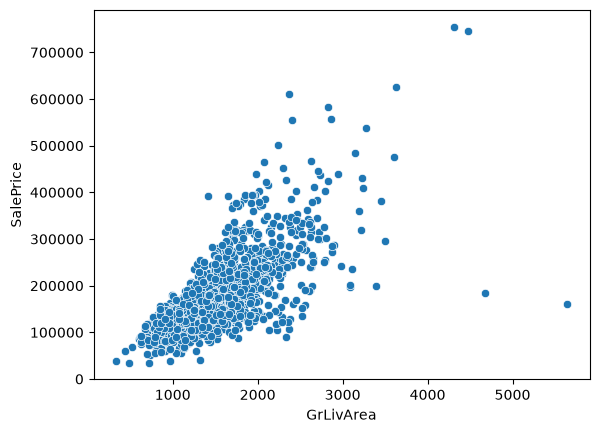

In [29]:
sns.scatterplot(data=df,x='GrLivArea',y='SalePrice')

có thể thấy mqh tuyến tính khá rõ giữ grlivare và saleprice có nghĩa là diện tích sống càng lớn thì giá nhà càng cao, nhưng ta có thể thấy 2 chấm nằm khoảng 4.600-5.600 ft có giá tầm 1.800 - 2000, 2 điểm này lệch hẳn ở xu hướng tăng của giá nhà. việc coi chúng là ngoại lai phù hợp hơn xử lý bằng IQR,z-score

vậy tôi NGUYỄN TRUNG HIẾU đề xuất các điền các missing values và xử lý outlies


## điền các giá trị 0 

In [ ]:
ZERO_FILL_COLS = [
    "GarageArea",
    "GarageCars",
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "TotalBsmtSF",
    "BsmtFullBath",
    "BsmtHalfBath",
]

## điền các giá trị none ( thể hiện không có các tiện ích)

In [ ]:
NA_SEMANTIC_MAP: dict[str, str] = {
    "PoolQC": "No Pool",
    "Alley": "No alley access",
    "Fence": "No Fence",
    "FireplaceQu": "No Fireplace",
    "GarageType": "No Garage",
    "GarageFinish": "No Garage",
    "GarageQual": "No Garage",
    "GarageCond": "No Garage",
    "BsmtQual": "No Basement",
    "BsmtCond": "No Basement",
    "BsmtExposure": "No Basement",
    "BsmtFinType1": "No Basement",
    "BsmtFinType2": "No Basement",
    "MiscFeature": "No Misc Feature",
}

## điền các median và mode cho các cột thiếu thật sự

In [ ]:
MEDIAN_FILL_COLS = [
    "LotFrontage",
]

# Các cột điền bằng Mode
MODE_FILL_COLS = [
    "MSZoning",
    "Utilities",
    "Exterior1st",
    "Exterior2nd",
    "Electrical",
    "KitchenQual",
    "Functional",
    "SaleType",
]